<div style="text-align: center; padding-top: 12%;">

# Convolutional Neural Networks

## DATA 301 @ WM

<figure class="no-fragment">
<center>
<a href="https://github.com/yanhai-xiong/DATA301-AML/blob/main/Module%205%20-%20Convolutional%20Neural%20Nets%20and%20Grid%20Search%20Algorithms/Section%201%20-%20Convolutional_Neural_Networks.ipynb" target="_blank">
    <img class="no-fragment"
         src="https://brand.github.com/_next/static/media/logo-03.cc5e5332.png"
         width="80px"/>
</a>
</center>
</figure>
</div>

# <font color='blue' size=5pt>From MLPs to Convolutional Neural Networks (CNNs)</font>

We have learned how **multilayer perceptrons (MLPs)** make predictions through forward propagation and learn parameters through **backpropagation and gradient descent**.

However, MLPs have limitations when processing structured data such as images:
- **Loss of spatial structure:** Flattening an image into a vector ignores the spatial relationships between neighboring pixels.
- **Too many parameters:** Fully connected layers require a large number of weights for high-dimensional inputs.
- **Limited translation awareness:** An MLP does not inherently recognize the same pattern when it appears at different locations.

<img src = "https://www.nvidia.com/content/nvidiaGDC/us/en_US/glossary/convolutional-neural-network/_jcr_content/root/responsivegrid/nv_container_1490534979/nv_image.coreimg.100.1070.png/1778648240226/neural-networks-pic1.png" width=300>

# **Standard Convolution**

<img src="https://assets-global.website-files.com/614c82ed388d53640613982e/646371e3bdc5ca90dee5331b_convolutional-neural-network%20(1).webp" width=600>

Source: https://www.superannotate.com/blog/guide-to-convolutional-neural-networks

[Additional Slides](https://docs.google.com/presentation/d/1vk8nROM9U3FFO6VnsNZNUM2Y3VPSeG3kTh20yuY7qRs/edit#slide=id.p1)



### Key Concepts

<div style="display: flex; justify-content: center; align-items: center; gap: 10px;">
    <img src="https://miro.medium.com/v2/resize:fit:1400/1*zUDC6dNc3rIOwTfRg3sEBw.png" width="400">
    <img src="https://almablog-media.s3.ap-south-1.amazonaws.com/9_d0e24ad09a.png" width="400">
</div>

In a standard convolution operation, a kernel (filter) slides over an input feature map, and at each position, it computes the dot product between the kernel weights and the corresponding input values. The kernel elements are applied to adjacent input pixels.
- **Kernel Size ($K$):** The dimensions of the kernel (e.g., $3 \times 3$).
- **Stride ($S$):** How many pixels the kernel moves after each operation.
- **Padding ($P$):** Adding zeros around the input to control the output size.

# Dilated Convolutions

<img src="https://media.springernature.com/lw1200/springer-static/image/art%3A10.1038%2Fs41598-025-92640-2/MediaObjects/41598_2025_92640_Fig3_HTML.png" width=400>

Dilated convolutions, also known as **atrous convolutions**, are a type of convolution operation where the convolutional kernel is expanded by inserting spaces (zeros) between its elements. This allows the convolution to have a larger **receptive field** without increasing the number of parameters or the computational cost significantly.
- **Standard Convolution ($ D = 1 $)**:
  The kernel covers a $ 3 \times 3 $ area of the input without any gaps.
- **Dilated Convolution ($ D = 2 $)**:
  The kernel elements are spaced out, covering a larger area. The receptive field becomes $ 5 \times 5 $, but the kernel still has only 9 parameters.

### **Visual Explanation**
<img  class = "no-fragment" src="https://media.springernature.com/lw1200/springer-static/image/art%3A10.1038%2Fs41598-025-92640-2/MediaObjects/41598_2025_92640_Fig3_HTML.png" width=300>

| Standard Kernel ($D=1$) | Dilated Kernel ($D=2$) |
|:---:|:---:|
| $\begin{bmatrix} w_{00} & w_{01} & w_{02} \\ w_{10} & w_{11} & w_{12} \\ w_{20} & w_{21} & w_{22} \end{bmatrix}$ | $\begin{bmatrix} w_{00} & 0 & w_{01} & 0 & w_{02} \\ 0 & 0 & 0 & 0 & 0 \\ w_{10} & 0 & w_{11} & 0 & w_{12} \\ 0 & 0 & 0 & 0 & 0 \\ w_{20} & 0 & w_{21} & 0 & w_{22} \end{bmatrix}$ |
| Effective size: $3\times3$ | Effective size: $5\times5$ |

### **Effect of Dilation on Receptive Field**
<img src="https://media.springernature.com/lw1200/springer-static/image/art%3A10.1038%2Fs41598-025-92640-2/MediaObjects/41598_2025_92640_Fig3_HTML.png" width=300>

- **Dilated Convolution**: Increases the receptive field exponentially without increasing the number of parameters or the computational cost linearly.
- **Effective Kernel Size Calculation**:
$$
K_{\text{effective}} = K + (K - 1) \times (D - 1) = D(K-1)+1
$$


### **Advantages and Considerations**

#### **Advantages**:
- **Efficient Contextual Understanding**: Captures global information without a significant increase in computation.
- **Parameter Efficiency**: Larger receptive fields without more parameters.
- **Flexibility**: Can be combined with different dilation rates in parallel or sequential layers to capture features at multiple scales.

#### **Considerations**:
- **Gridding Artifacts**: High dilation rates can cause checkerboard patterns or gridding artifacts in the output because of the sparse sampling of input pixels.
- **Balancing Dilation and Kernel Size**: Choosing the right combination is crucial for optimal performance.



### **Real-World Examples**

Dilated convolutions are particularly useful when a model needs to capture both local details and broader context without significantly increasing computational cost.

- Semantic Segmentation: Assigns a class label to every pixel in an image (e.g., road, car, pedestrian). Dilated convolutions expand the receptive field without reducing the spatial resolution, helping the model capture broader context while preserving fine details.
- **[DeepLab](https://arxiv.org/pdf/1606.00915)  Series**: Uses dilated convolutions with varying dilation rates to capture multi-scale information in images.
- **[WaveNet](https://arxiv.org/abs/1609.03499) (Audio and Time-Series)** uses dilated convolutions to model long-range dependencies efficiently.


# Arithmetic of Convolutions

 It's essential to understand how the dimensions of your data change after each convolutional layer. This involves calculating the output size based on the input size and the convolution parameters such as 
 - kernel size,
 - stride,
 - padding, and
 - dilation. 







## **Basics of 2D Convolutions**

In PyTorch, a 2D convolutional layer is created using `nn.Conv2d`. The key parameters are:

- **`in_channels`**: Number of channels in the input image.
- **`out_channels`**: Number of channels produced by the convolution.
- **`kernel_size`**: Size of the convolving kernel (filter).
- **`stride`**: Stride of the convolution (how the filter moves over the input).
- **`padding`**: Zero-padding added to both sides of the input.
- **`dilation`**: Spacing between kernel elements.



## Step 1 - Stride = 1, No Padding

<img src="https://adeshpande3.github.io/assets/Stride1.png" width="400">

**Mathematically**, for a 2D input, the output $y[i,j]$ of a standard convolution (stride = 1, no padding) is calculated as:
$$
y[i,j] = \sum_{m=0}^{K-1} \sum_{n=0}^{K-1} x[i+m,j+n] \cdot w[m,n]
$$


**Output Size** (for each spatial dimension $I=H \textit{ or } W$):
$$
O =  ( {I-K} )+1
$$


- $x$: Input feature map.
- $w$: Kernel weights.
- $K$: Kernel size (assuming a square kernel).
- $i,j$: Output spatial position.
- $I$: Input size.
- $P$: Padding size.
- $S$: Stride.
- $O$: Output size.

## Step 2 - **With stride ($S$) and padding ($P$):**
<img src="https://adeshpande3.github.io/assets/Stride2.png" width="400">

$$
y[i,j] = \sum_{m=0}^{K-1} \sum_{n=0}^{K-1}
x_p[iS+m,jS+n] \cdot w[m,n]
$$
where $x_p$ is the input after padding.

**Output Size** (for each spatial dimension):
$$
O = \left\lfloor \frac{I+2P-K}{S} \right\rfloor+1
$$


## Step 3 - With $S$, $P$, and $D$
<img src="https://miro.medium.com/v2/resize:fit:1400/1*0OEU2VQHKtJW-kMiiynIWg.png" width="400">

$$
y[i,j] = \sum_{m=0}^{K-1} \sum_{n=0}^{K-1}
x_p[iS+ Dm,jS+ Dn] \cdot w[m,n]
$$

**Output Size** (for each spatial dimension):
$$
O = \left\lfloor \frac{I + 2 P - (D \times (K - 1) + 1)}{S}  \right\rfloor+ 1
$$

- $ x $: Input feature map.
- $ w $: Kernel weights.
- $ K $: Kernel size.
- $ D $: Dilation rate.

### **Step-by-Step Examples**

#### **Example 1: Basic Convolution**

**Parameters**:
- Input Size: $ H_{in} = 32 $, $ W_{in} = 32 $
- Kernel Size: $ K = 3 $
- Padding: $ P = 1 $
- Stride: $ S = 1 $
- Dilation: $ D = 1 $

**Calculation**:
$$
\text{Output Size} = \left\lfloor \frac{32 + 2 \times 1 - 1 \times (3 - 1) - 1}{1} + 1 \right\rfloor = 32
$$

**Explanation**: With padding of 1 and a kernel size of 3, the output size remains the same as the input size.

---

#### **Example 2: Convolution with No Padding**

**Parameters**:
- Input Size: $ H_{in} = 32 $, $ W_{in} = 32 $
- Kernel Size: $ K = 5 $
- Padding: $ P = 0 $
- Stride: $ S = 1 $
- Dilation: $ D = 1 $

**Calculation**:
$$
\text{Output Size} = \left\lfloor \frac{32 + 0 - 1 \times (5 - 1) - 1}{1} + 1 \right\rfloor = 28
$$

**Explanation**: Without padding, the output size decreases because the kernel cannot slide over the edges of the input.

---

#### **Example 3: Convolution with Stride**

**Parameters**:
- Input Size: $ H_{in} = 64 $, $ W_{in} = 64 $
- Kernel Size: $ K = 3 $
- Padding: $ P = 0 $
- Stride: $ S = 2 $
- Dilation: $ D = 1 $

**Calculation**:
$$
\text{Output Size} = \left\lfloor \frac{64 + 0 - 1 \times (3 - 1) - 1}{2} + 1 \right\rfloor = 31
$$

**Explanation**: A stride of 2 effectively halves the spatial dimensions of the output.

---

#### **Example 4: Convolution with Dilation**

**Parameters**:
- Input Size: $ H_{in} = 32 $, $ W_{in} = 32 $
- Kernel Size: $ K = 3 $
- Padding: $ P = 1 $
- Stride: $ S = 1 $
- Dilation: $ D = 2 $

**Effective Kernel Size**:
$$
K_{\text{effective}} = D \times (K - 1) + 1 = 2 \times 2 + 1 = 5
$$

**Calculation**:
$$
\text{Output Size} = \left\lfloor \frac{32 + 2 \times 1 - 5 - 1}{1} + 1 \right\rfloor = 29
$$

**Explanation**: Dilation increases the effective kernel size, which reduces the output size.



## **Practical Tips**

- **Consistent Output Size**: To keep the output size the same as the input size, adjust the padding appropriately. For a kernel size $ K $ and dilation $ D $, padding should be:
  $$
  P = \frac{D \times (K - 1)}{2}
  $$
- **Avoiding Fractional Outputs**: Ensure that the numerator in the output size formula is divisible by the stride to avoid fractional outputs.
- **Stacking Layers**: When stacking multiple convolutional layers, compute the output size after each layer to ensure compatibility.



### **Example Calculation**

Let's work through an example to see how dilation affects the output size.

**Parameters**:

- Input Size: $ H_{in} = W_{in} = 32 $
- Kernel Size: $ K = 3 $
- Dilation Rate: $ D = 2 $
- Stride: $ S = 1 $
- Padding: $ P = D $

**Effective Kernel Size**:

$$
K_{\text{effective}} = K + (K - 1) \times (D - 1) = 3 + 2 \times 1 = 5
$$

**Output Size Calculation**:

$$
\text{Output Size} = \left\lfloor \frac{H_{in} + 2P - K_{\text{effective}}}{S} + 1 \right\rfloor
$$

Substitute the values:

$$
\text{Output Size} = \left\lfloor \frac{32 + 2 \times 2 - 5}{1} + 1 \right\rfloor = \left\lfloor \frac{32 + 4 - 5}{1} + 1 \right\rfloor = \left\lfloor 31 + 1 \right\rfloor = 32
$$

**Explanation**:

- The dilation increases the effective size of the kernel to $ 5 \times 5 $.
- Padding is set to $ P = D = 2 $ to maintain the output size.
- The output size remains $ 32 \times 32 $.

## <font color='blue' size=5pt>Activation Layer and Pooling Layer</font>
**Activation Layer** (most commenly ReLU) to introduce nonlinearity.

<img src="https://b2633864.assetcdn.net/2633864/wp-content/uploads/2021/05/relu_activation.png?lossy=2&strip=1&webp=1" width="300">


**Max Pooling Layer** reduces the spatial dimensions of a feature map by selecting the **maximum value** within each local region.

<img src="https://miro.medium.com/1*px_9GmRXLOAmscAN54d3xw.jpeg" width="300">




## Typical CNN Processing Sequence

<img src="https://miro.medium.com/v2/resize:fit:1200/1*XbuW8WuRrAY5pC4t-9DZAQ.jpeg" width="300">

$$
\boxed{
\text{Input}
\;\longrightarrow\;
\text{Convolution}
\;\longrightarrow\;
\text{ReLU}
\;\longrightarrow\;
\text{Max Pooling}
\;\longrightarrow\;
\text{Next Layer}
}
$$

- **Convolution:** Extracts local features using learnable filters.
- **Activation:** Introduces nonlinearity.
- **Max Pooling:** Reduces spatial dimensions while retaining strong feature responses.

**Note:** Pooling is optional in modern CNNs. Strided convolutions can also perform spatial downsampling.

### **Dropout Layer (Optional Regularization)**
<img src="https://nagadakos.github.io/images/dropout.gif" width="300">

Dropout is a regularization technique used to **reduce overfitting** by randomly setting some activations to zero during **training**.
- **Reduces overfitting**
- **Training only**
- **No learnable parameters**
- **Optional** Not every CNN requires dropout, especially when other regularization techniques (e.g., weight decay, data augmentation) are sufficient.


## **Example: Designing a Convolutional Neural Network**

Suppose you have the following architecture:

1. **Conv Layer 1**:
   - Input Size: $ 64 \times 64 $
   - Kernel Size: $ 3 $
   - Padding: $ 1 $
   - Stride: $ 1 $
   - Output Size: $ 64 \times 64 $ (calculated using the formula)

2. **Max Pooling Layer**:
   - Kernel Size: $ 2 $
   - Stride: $ 2 $
   - Output Size: $ 32 \times 32 $

3. **Conv Layer 2**:
   - Input Size: $ 32 \times 32 $
   - Kernel Size: $ 3 $
   - Padding: $ 1 $
   - Stride: $ 1 $
   - Output Size: $ 32 \times 32 $

**Explanation**: By carefully choosing the parameters, you can design a network that progressively reduces spatial dimensions in a controlled manner.




## Applications Include

1. **Image Classification**:
   - **Object Recognition**: Identifying objects within an image (e.g., recognizing dogs, cats, cars).
   - **Scene Classification**: Categorizing the scene depicted in an image (e.g., beach, forest, city).

2. **Object Detection**:
   - **Face Detection**: Detecting human faces in images for applications like security, photo tagging, and more.
   - **Pedestrian Detection**: Used in autonomous driving and surveillance systems.

3. **Image Segmentation**:
   - **Semantic Segmentation**: Classifying each pixel in an image into a category (e.g., separating roads, buildings, cars in a cityscape).
   - **Instance Segmentation**: Distinguishing between different instances of objects in an image (e.g., identifying and separating multiple people).

4. **Medical Imaging**:
   - **Disease Diagnosis**: Analyzing medical images (e.g., X-rays, MRIs) to detect diseases like cancer, Alzheimer's, and retinal diseases.
   - **Organ Segmentation**: Identifying and segmenting organs in medical scans for surgical planning and diagnosis.

5. **Self-driving Cars**:
   - **Road Sign Recognition**: Detecting and classifying traffic signs.
   - **Lane Detection**: Identifying lane boundaries on the road.
   - **Obstacle Detection**: Detecting pedestrians, other vehicles, and obstacles.

6. **Facial Recognition and Authentication**:
   - **Face Recognition**: Identifying or verifying a person from an image or video frame.
   - **Emotion Recognition**: Analyzing facial expressions to determine emotions.

7. **Robotics and Automation**:
   - **Object Grasping**: Identifying objects and determining how to grasp them in robotic manipulation.
   - **Navigation**: Helping robots understand their environment for autonomous navigation.

8. **Augmented Reality (AR) and Virtual Reality (VR)**:
   - **Object Tracking**: Tracking objects in real-time to augment digital information onto the real world.
   - **Environment Understanding**: Understanding and mapping the environment for immersive VR experiences.

9. **Natural Language Processing (NLP)**:
   - **Text Classification**: Classifying text into categories (e.g., spam detection, sentiment analysis).
   - **Character Recognition**: Recognizing handwritten or printed text from images (e.g., OCR).

10. **Art and Creativity**:
    - **Style Transfer**: Applying the style of one image to another (e.g., making a photo look like a painting).
    - **Image Generation**: Creating new images from scratch (e.g., GANs for generating realistic photos).

11. **Super-Resolution and Image Enhancement**:
    - **Image Denoising**: Removing noise from images to enhance quality.
    - **Image Super-Resolution**: Increasing the resolution of images for better clarity and detail.

# Code Applications

### **Implementing CNN in PyTorch**

**Example**:

```python
import torch
import torch.nn as nn

# Define a dilated convolutional layer
conv_layer = nn.Conv2d(
    in_channels=16,
    out_channels=32,
    kernel_size=3,
    stride=1,
    padding=2,   # Adjust padding to maintain output size
    dilation=2   # Dilation rate
)

# Input tensor with shape (batch_size, in_channels, height, width)
input_tensor = torch.randn(1, 16, 32, 32)

# Output tensor
output_tensor = conv_layer(input_tensor)

print(f"Output shape: {output_tensor.shape}")
```

**Note on Padding**:

- If you want to compute the padding needed to maintain the output size:

  $$
  P = D \times \frac{K - 1}{2}
  $$

## Example 1 - Fashion MNIST

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

In [2]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
device

device(type='cuda')

In [5]:
# Define a transform to normalize the data
# transforms.ToTensor(): Converts pixel values from integers in \([0,255]\)
#   to floating-point values in \([0,1]\).
#   Changes the image shape from (H, W, C) to (C, H, W).
# transforms.Normalize((0.5,), (0.5,)):
#   Normalize and rescale pixel values to \([-1,1]\)
transform = transforms.Compose([
    transforms.ToTensor(), #
    transforms.Normalize((0.5,), (0.5,))
])

In [6]:
# Download and load the training and test datasets
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
# you can specify batsh size for the test if you plan to check the results at each time of the training process
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 164kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.8MB/s]


In [7]:
for X, y in train_loader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break
# Define the class names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


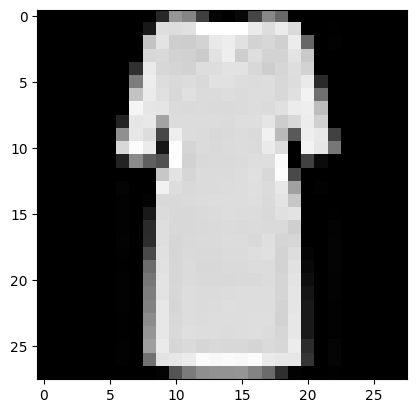

Dress


In [8]:
# look at some sample images
i = 23
plt.imshow(X[i,0,:],cmap='gray')
plt.show()
print(class_names[y[i].item()])

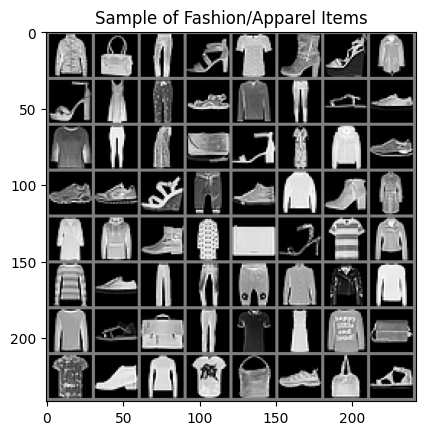

First Label: Pullover


In [9]:
# Function to display images
def imshow(img, label):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title('Sample of Fashion/Apparel Items')
    #plt.title(f'First Item: {class_names[label]}')
    plt.show()

# Get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images
imshow(torchvision.utils.make_grid(images), labels[0])

# Display the name of the label for the first image in the batch
print(f'First Label: {class_names[labels[29]]}')

### What happens if we do not use convolutions/feature extractions

In [10]:
class NeuralNetwork(nn.Module): # almost always the input is the same
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential( # it means we have a sequence of layers of neurons
            nn.Linear(28*28, 256), # this one is the first layer of the network
            nn.ReLU(), # we want here the simplest activations
            nn.Linear(256, 512), # the second layer of neurons, here we got 512 neurons
            nn.ReLU(), # again simple activations, the same for all such as ReLU
            nn.Linear(512, 10) # output -> 10 neurons b/c we predict ten probability values
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device) # this means your network will run on the device you chose
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [12]:
# here we define the training procedure
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader): # this is the must-have iterator
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 50 == 0:
            loss, current = loss.item(), (batch + 1)*len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [13]:
# to evaluate the trained model onto the Test data
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval() # we set the model in evaluation state
    test_loss, correct = 0, 0
    with torch.no_grad(): # a must-have for model.eval()
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [14]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_loader, model, loss_fn, optimizer)
    test(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.315455  [   64/60000]
loss: 0.643309  [ 3264/60000]
loss: 0.513793  [ 6464/60000]
loss: 0.439682  [ 9664/60000]
loss: 0.557855  [12864/60000]
loss: 0.670002  [16064/60000]
loss: 0.529760  [19264/60000]
loss: 0.430831  [22464/60000]
loss: 0.391035  [25664/60000]
loss: 0.714772  [28864/60000]
loss: 0.484874  [32064/60000]
loss: 0.488162  [35264/60000]
loss: 0.345751  [38464/60000]
loss: 0.492495  [41664/60000]
loss: 0.304786  [44864/60000]
loss: 0.547246  [48064/60000]
loss: 0.374936  [51264/60000]
loss: 0.419396  [54464/60000]
loss: 0.491938  [57664/60000]
Test Error: 
 Accuracy: 84.8%, Avg loss: 0.419898 

Epoch 2
-------------------------------
loss: 0.459684  [   64/60000]
loss: 0.315535  [ 3264/60000]
loss: 0.411485  [ 6464/60000]
loss: 0.559328  [ 9664/60000]
loss: 0.296605  [12864/60000]
loss: 0.448023  [16064/60000]
loss: 0.376269  [19264/60000]
loss: 0.427989  [22464/60000]
loss: 0.382327  [25664/60000]
loss: 0.464028  [28864/60000

### The benefit of convolutions:

In [15]:
# Define the convolutional model
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(1, 50, kernel_size=3, padding=1),
            nn.BatchNorm2d(50), # this is the z-score StandardScaler
            nn.ReLU(), # activations
            nn.MaxPool2d(kernel_size=2, stride=2), # summarizations to address the enlarged memory footprint
            nn.Dropout(p=0.25) # cutting dendrites randomly to prevent dead neurons
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(50, 100, kernel_size=3),
            nn.BatchNorm2d(100),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
            nn.Dropout(p=0.25)
        )
        self.fc1 = nn.Linear(100*6*6, 1000) # here we pass on the 100 features extracted and each feature is now 6x6
        self.fc2 = nn.Linear(1000, 10) # is non-negotiable

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out) # here we got all the 100 features
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.fc2(out)
        return out

model = CNN().to(device)

# Define the loss function and optimizer
loss_fn = nn.CrossEntropyLoss() # it's a must: choose the correct loss function
optimizer = optim.Adam(model.parameters(), lr=0.001) # we chose adaptive momentum gradient descent as our optimizer

# Train the model
num_epochs = 10




### How to calculate the correct sizes



#### **Layer 1:**

1. **Input Size:** $28 \times 28$
2. **Convolution (`nn.Conv2d`):**
   - Kernel size = 3
   - Padding = 1
   - Stride = 1 (default for `nn.Conv2d`)
   - Formula:
     $$
     \text{Output Size} = \left\lfloor \frac{\text{Input Size} + 2 \cdot \text{Padding} - \text{Kernel Size}}{\text{Stride}} \right\rfloor + 1
     $$
   - Substituting values:
     $$
     \text{Output Size} = \left\lfloor \frac{28 + 2 \cdot 1 - 3}{1} \right\rfloor + 1 = 28
     $$
   - Output size after convolution: $28 \times 28$, with 50 channels.

3. **Batch Normalization (`nn.BatchNorm2d`) and ReLU:**
   - These do not change the spatial dimensions.
   - Output size remains $28 \times 28 \times 50$.

4. **MaxPooling (`nn.MaxPool2d`):**
   - Kernel size = 2, Stride = 2
   - Formula:
     $$
     \text{Output Size} = \left\lfloor \frac{\text{Input Size} - \text{Kernel Size}}{\text{Stride}} \right\rfloor + 1
     $$
   - Substituting values:
     $$
     \text{Output Size} = \left\lfloor \frac{28 - 2}{2} \right\rfloor + 1 = 14
     $$
   - Output size after pooling: $14 \times 14 \times 50$.

5. **Dropout (`nn.Dropout`):**
   - Dropout randomly disables neurons but does not affect spatial dimensions.
   - Output size remains $14 \times 14 \times 50$.

---

#### **Layer 2:**

1. **Input Size:** $14 \times 14$ (from the output of Layer 1).
2. **Convolution (`nn.Conv2d`):**
   - Kernel size = 3
   - Padding = 0 (default for `nn.Conv2d`)
   - Stride = 1 (default for `nn.Conv2d`)
   - Formula:
     $$
     \text{Output Size} = \left\lfloor \frac{\text{Input Size} + 2 \cdot \text{Padding} - \text{Kernel Size}}{\text{Stride}} \right\rfloor + 1
     $$
   - Substituting values:
     $$
     \text{Output Size} = \left\lfloor \frac{14 + 2 \cdot 0 - 3}{1} \right\rfloor + 1 = 12
     $$
   - Output size after convolution: $12 \times 12$, with 100 channels.

3. **Batch Normalization (`nn.BatchNorm2d`) and ReLU:**
   - These do not change the spatial dimensions.
   - Output size remains $12 \times 12 \times 100$.

4. **MaxPooling (`nn.MaxPool2d`):**
   - Kernel size = 2, Stride = 2
   - Formula:
     $$
     \text{Output Size} = \left\lfloor \frac{\text{Input Size} - \text{Kernel Size}}{\text{Stride}} \right\rfloor + 1
     $$
   - Substituting values:
     $$
     \text{Output Size} = \left\lfloor \frac{12 - 2}{2} \right\rfloor + 1 = 6
     $$
   - Output size after pooling: $6 \times 6 \times 100$.

5. **Dropout (`nn.Dropout`):**
   - Dropout does not affect spatial dimensions.
   - Output size remains $6 \times 6 \times 100$.

---

#### Final Output:
- After `layer1`: $14 \times 14 \times 50$
- After `layer2`: $6 \times 6 \times 100$



In [16]:
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = loss_fn(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i+1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

Epoch [1/10], Step [100/938], Loss: 0.6179
Epoch [1/10], Step [200/938], Loss: 0.5577
Epoch [1/10], Step [300/938], Loss: 0.4858
Epoch [1/10], Step [400/938], Loss: 0.3537
Epoch [1/10], Step [500/938], Loss: 0.5197
Epoch [1/10], Step [600/938], Loss: 0.5005
Epoch [1/10], Step [700/938], Loss: 0.3914
Epoch [1/10], Step [800/938], Loss: 0.5161
Epoch [1/10], Step [900/938], Loss: 0.4324
Epoch [2/10], Step [100/938], Loss: 0.5546
Epoch [2/10], Step [200/938], Loss: 0.3224
Epoch [2/10], Step [300/938], Loss: 0.4957
Epoch [2/10], Step [400/938], Loss: 0.3125
Epoch [2/10], Step [500/938], Loss: 0.2783
Epoch [2/10], Step [600/938], Loss: 0.1768
Epoch [2/10], Step [700/938], Loss: 0.4168
Epoch [2/10], Step [800/938], Loss: 0.2424
Epoch [2/10], Step [900/938], Loss: 0.2924
Epoch [3/10], Step [100/938], Loss: 0.2888
Epoch [3/10], Step [200/938], Loss: 0.2894
Epoch [3/10], Step [300/938], Loss: 0.2627
Epoch [3/10], Step [400/938], Loss: 0.3329
Epoch [3/10], Step [500/938], Loss: 0.3242
Epoch [3/10

In [17]:
# Evaluate the model
model.eval()  # Set the model to evaluation mode
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f'Accuracy of the model on the test images: {100 * correct / total:.2f}%')

Accuracy of the model on the test images: 91.45%


In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_loader, model, loss_fn, optimizer)
    test(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.402690  [   64/60000]
loss: 1.199077  [ 3264/60000]
loss: 1.126759  [ 6464/60000]
loss: 0.849344  [ 9664/60000]
loss: 0.382158  [12864/60000]
loss: 0.597148  [16064/60000]
loss: 0.373733  [19264/60000]
loss: 0.500315  [22464/60000]
loss: 0.480907  [25664/60000]
loss: 0.643764  [28864/60000]
loss: 0.442720  [32064/60000]
loss: 0.264154  [35264/60000]
loss: 0.640923  [38464/60000]
loss: 0.568215  [41664/60000]
loss: 0.541633  [44864/60000]
loss: 0.396583  [48064/60000]
loss: 0.208528  [51264/60000]
loss: 0.346195  [54464/60000]
loss: 0.494482  [57664/60000]
Test Error: 
 Accuracy: 87.8%, Avg loss: 0.358058 

Epoch 2
-------------------------------
loss: 0.292560  [   64/60000]
loss: 0.177792  [ 3264/60000]
loss: 0.297991  [ 6464/60000]
loss: 0.449457  [ 9664/60000]
loss: 0.332533  [12864/60000]
loss: 0.388777  [16064/60000]
loss: 0.504602  [19264/60000]
loss: 0.318129  [22464/60000]
loss: 0.273326  [25664/60000]
loss: 0.757337  [28864/60000

## Exercise: Apply similar designs for the US Postal Service data (MNIST), and the handwritten letters, EMNIST data.

In [ ]:
# Download and load the training and test datasets
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, transform=transform, download=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
# you can specify batsh size for the test if you plan to check the results at each time of the training process
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:01<00:00, 5079224.31it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 134439.42it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:01<00:00, 1257690.00it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 5486903.45it/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



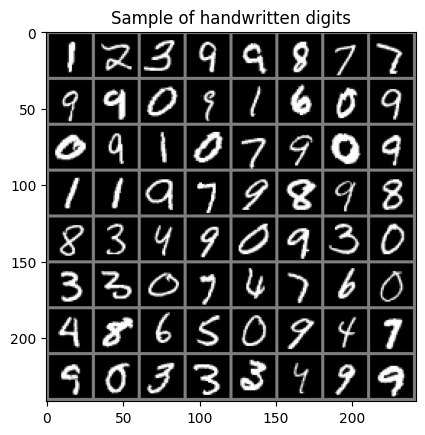

First Label: 1


In [ ]:
# Function to display images
def imshow(img, label):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title('Sample of handwritten digits')
    #plt.title(f'First Item: {label}')
    plt.show()

# Get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images
imshow(torchvision.utils.make_grid(images), labels[0])

# Display the name of the label for the first image in the batch
print(f'First Label: {labels[0]}')

## Exercise: Develop a CNN for the [CiFar10](https://www.cs.toronto.edu/~kriz/cifar.html) data.